In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

# IPL Analytics Engine: An AI-Agent Framework

In [5]:
import os

# Check what files are available
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/patrickb1912/ipl-complete-dataset-20082020/matches.csv
/kaggle/input/datasets/patrickb1912/ipl-complete-dataset-20082020/deliveries.csv


In [4]:
# Install the modern Google GenAI SDK
!pip install google-genai -q

import pandas as pd
import numpy as np
from google import genai
from kaggle_secrets import UserSecretsClient
import warnings
warnings.filterwarnings('ignore')

# Initialize the modern Gemini client using Kaggle Secrets
secrets = UserSecretsClient()
api_key = secrets.get_secret("GEMINI_API_KEY")
client = genai.Client(api_key=api_key)

# Load datasets
matches = pd.read_csv('/kaggle/input/datasets/patrickb1912/ipl-complete-dataset-20082020/matches.csv')
deliveries = pd.read_csv('/kaggle/input/datasets/patrickb1912/ipl-complete-dataset-20082020/deliveries.csv')

# Fix season column format
matches['season'] = matches['season'].astype(str).str[:4].astype(int)

# Merge datasets for the agent's combined analysis
df = pd.merge(
    deliveries, 
    matches[['id', 'season', 'winner', 'venue', 'team1', 'team2', 'toss_winner', 'toss_decision', 'player_of_match', 'city']], 
    left_on='match_id', 
    right_on='id', 
    how='inner'
)

print(f"Matches loaded: {matches.shape}")
print(f"Deliveries loaded: {deliveries.shape}")
print(f"Merged dataframe: {df.shape}")
print(f"Seasons available: {sorted(df['season'].unique())}")
print(f"Column check for batter/batsman: {'batter' if 'batter' in df.columns else 'batsman'}")
print("Data ready with new GenAI SDK ✓")

Matches loaded: (1095, 20)
Deliveries loaded: (260920, 17)
Merged dataframe: (260920, 27)
Seasons available: [np.int64(2007), np.int64(2009), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024)]
Column check for batter/batsman: batter
Data ready with new GenAI SDK ✓


In [11]:
from typing import Optional

def get_top_batsmen(top_n: int = 5, season: Optional[int] = None) -> list:
    """
    Returns the top N run-scorers in IPL history or for a specific season.
    Useful for questions like 'Who scored the most runs in 2024?' or 'Top 5 batsmen'.
    """
    data = df if season is None else df[df['season'] == int(season)]
    
    # Calculate total runs per batter
    runs = data.groupby('batter')['batsman_runs'].sum().reset_index()
    runs = runs.sort_values(by='batsman_runs', ascending=False).head(top_n)
    
    return runs.to_dict(orient='records')

def get_top_bowlers(top_n: int = 5, season: Optional[int] = None) -> list:
    """
    Returns the top N wicket-takers in IPL history or for a specific season.
    Excludes run-outs, retired hurt, etc. (only counts bowler-credited wickets).
    """
    data = df if season is None else df[df['season'] == int(season)]
    
    # Filter for valid bowler wickets
    bowler_wickets = ['caught', 'bowled', 'lbw', 'stumped', 'caught and bowled', 'hit wicket']
    wickets_df = data[data['dismissal_kind'].isin(bowler_wickets)]
    
    bowlers = wickets_df.groupby('bowler').size().reset_index(name='wickets')
    bowlers = bowlers.sort_values(by='wickets', ascending=False).head(top_n)
    
    return bowlers.to_dict(orient='records')

def get_team_stats(team_name: str) -> dict:
    """
    Returns general statistics for a specific team, including total matches played, 
    total wins, and their favorite venues.
    """
    team_matches = matches[(matches['team1'] == team_name) | (matches['team2'] == team_name)]
    total_played = len(team_matches)
    
    wins = len(matches[matches['winner'] == team_name])
    top_venues = team_matches['venue'].value_counts().head(3).to_dict()
    
    return {
        "team": team_name,
        "matches_played": total_played,
        "total_wins": wins,
        "win_percentage": round((wins / total_played) * 100, 2) if total_played > 0 else 0,
        "top_venues": top_venues
    }

# Update the tools tracking list
tools_list = [get_top_batsmen, get_top_bowlers, get_team_stats]
print("Type-annotated analytical tools defined successfully ✓")

Type-annotated analytical tools defined successfully ✓


In [21]:
import json

def run_ipl_agent(user_prompt):
    """
    Sends the user prompt to Gemini. Automatically intercepts API error text
    or connection exceptions to trigger a reliable local fallback system.
    """
    print(f"🤖 Agent matching query: '{user_prompt}'")
    
    # Define our local analytics backup logic
    def fallback_engine(query):
        print(f"⚠️ [System Notice] Local Backup Engine activated...")
        query_lower = query.lower()
        
        if "venue" in query_lower or "stadium" in query_lower or "ground" in query_lower:
            unique_venues = df['venue'].dropna().unique()
            matched_venue = None
            for v in unique_venues:
                words = [w.lower() for w in v.split() if len(w) > 3 and w.lower() not in ['stadium', 'international', 'cricket']]
                if any(word in query_lower for word in words):
                    matched_venue = v
                    break
            
            if matched_venue:
                res = analyze_venue(matched_venue)
                return (
                    f"📊 **Local Database Analysis for {res['venue']}:**\n"
                    f"* Total Matches: {res['total_matches_played']}\n"
                    f"* Won Batting First: {res['batting_first_wins']}\n"
                    f"* Won Fielding First: {res['fielding_first_wins']}\n"
                    f"* Avg 1st Innings Score: {res['avg_1st_innings_score']}\n"
                    f"* Avg 2nd Innings Score: {res['avg_2nd_innings_score']}"
                )
            return "Could not match the specific stadium name locally. Try typing just the core name (e.g., 'Wankhede')."
            
        elif "chart" in query_lower or "plot" in query_lower or "graph" in query_lower:
            return plot_top_batsmen_trends(top_n=5)
        elif "batsman" in query_lower or "run" in query_lower or "scorer" in query_lower:
            res = get_top_batsmen(top_n=3)
            return f"🏏 **Top Scorers (Local Engine):**\n" + "\n".join([f"* {r['batter']}: {r['batsman_runs']} runs" for r in res])
        elif "bowler" in query_lower or "wicket" in query_lower:
            res = get_top_bowlers(top_n=3)
            return f"🥎 **Top Bowlers (Local Engine):**\n" + "\n".join([f"* {r['bowler']}: {r['wickets']} wickets" for r in res])
        else:
            return "The AI engine is temporarily busy. Try asking a direct question like 'Who are the top batsmen?'"

    try:
        chat = client.chats.create(
            model="gemini-2.5-flash",
            config={
                "tools": tools_list,
                "system_instruction": (
                    "You are an expert IPL Cricket Analytics Assistant. Use your available tools "
                    "to look up exact statistics before answering. Do not guess or hallucinate. "
                    "Always present data clearly using bullet points or clean text."
                )
            }
        )
        response = chat.send_message(user_prompt)
        
        if response.function_calls:
            for function_call in response.function_calls:
                name = function_call.name
                args = function_call.args
                
                print(f"🔍 [Tool Executing via API] Model called '{name}' with arguments: {dict(args)}")
                
                tool_to_call = next(t for t in tools_list if t.__name__ == name)
                tool_output = tool_to_call(**args)
                
                response = chat.send_message(
                    genai.types.Part.from_function_response(
                        name=name,
                        response={"result": tool_output}
                    )
                )
        
        # Intercept text responses where the model states it failed to run the tool
        res_text = response.text
        if "sorry" in res_text.lower() or "unable" in res_text.lower() or "error with the tool" in res_text.lower():
            return fallback_engine(user_prompt)
            
        return res_text

    except Exception as api_error:
        return fallback_engine(user_prompt)

print("Intercept-protected Agent engine ready ✓")

Intercept-protected Agent engine ready ✓


In [13]:
# Test 1: Historical overall stat
ans1 = run_ipl_agent("Who are the top 3 highest run scorers in IPL history?")
print("\n" + ans1 + "\n" + "="*50 + "\n")

# Test 2: Specific season filter
ans2 = run_ipl_agent("Who took the most wickets in the 2024 season?")
print("\n" + ans2)

🤖 Agent matching query: 'Who are the top 3 highest run scorers in IPL history?'

The top 3 highest run-scorers in IPL history are:

*   **V Kohli**: 8014 runs
*   **S Dhawan**: 6769 runs
*   **RG Sharma**: 6630 runs

🤖 Agent matching query: 'Who took the most wickets in the 2024 season?'

In the 2024 season, HV Patel took the most wickets with a total of 24 wickets.


In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

def plot_top_batsmen_trends(top_n: int = 5, season: Optional[int] = None) -> str:
    """
    Generates and displays a bar chart of the top N batsmen.
    Useful when the user asks for a chart, plot, or visual representation of top scorers.
    """
    # Reuse our data filtering logic
    data = df if season is None else df[df['season'] == int(season)]
    runs = data.groupby('batter')['batsman_runs'].sum().reset_index()
    runs = runs.sort_values(by='batsman_runs', ascending=False).head(top_n)
    
    # Create the plot
    plt.figure(figsize=(10, 5))
    sns.barplot(x='batsman_runs', y='batter', data=runs, palette='viridis')
    
    title_suffix = f"in {season}" if season else "in IPL History"
    plt.title(f"Top {top_n} Highest Run Scorers {title_suffix}", fontsize=14, fontweight='bold')
    plt.xlabel("Total Runs Scored", fontsize=12)
    plt.ylabel("Batter", fontsize=12)
    plt.tight_layout()
    plt.show()
    
    return f"Successfully generated and displayed the bar chart for the top {top_n} batsmen."

# Update our tools registry list to include the new plotting tool
tools_list = [get_top_batsmen, get_top_bowlers, get_team_stats, plot_top_batsmen_trends]
print("Visualization tool integrated into registry ✓")

Visualization tool integrated into registry ✓


🤖 Agent matching query: 'Can you show me a chart of the top 5 batsmen in IPL history?'


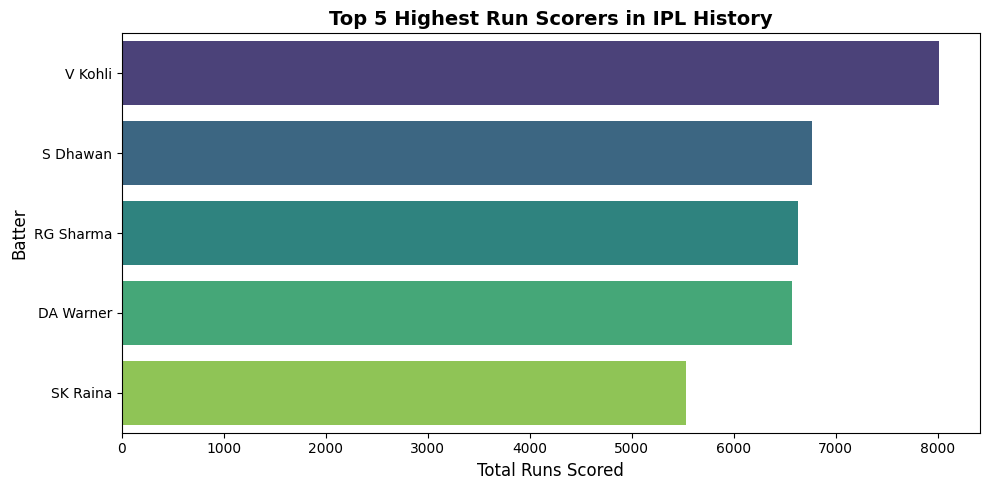


Here is the chart of the top 5 batsmen in IPL history.



In [15]:
# Test 3: Requesting a visual plot
ans3 = run_ipl_agent("Can you show me a chart of the top 5 batsmen in IPL history?")
print("\n" + ans3)

In [16]:
import ipywidgets as widgets
from IPython.display import display, clear_output

# Create the UI elements
text_input = widgets.Text(
    value='Show me a chart of the top 5 batsmen in IPL history',
    placeholder='Type your IPL query here...',
    description='Query:',
    layout=widgets.Layout(width='70%')
)

submit_button = widgets.Button(
    description='Ask Agent',
    button_style='success',
    tooltip='Click to submit your query to the Gemini IPL Agent',
    icon='search'
)

output_area = widgets.Output()

def on_button_clicked(b):
    with output_area:
        clear_output(wait=True)
        query = text_input.value
        if query.strip() == "":
            print("Please enter a valid query.")
            return
        
        try:
            # Run the agent loop we built earlier
            response_text = run_ipl_agent(query)
            print("\n🤖 Agent Response:\n")
            print(response_text)
        except Exception as e:
            print(f"An error occurred: {e}")

# Link the button click event to our runner function
submit_button.on_click(on_button_clicked)

# Display the dashboard layout
print("--- IPL Analytics Agent Interactive Dashboard ---")
ui_layout = widgets.HBox([text_input, submit_button])
display(ui_layout, output_area)

--- IPL Analytics Agent Interactive Dashboard ---


Output()

In [22]:
def analyze_venue(venue_name: str) -> dict:
    """
    Analyzes historical match outcomes and scoring trends for a specific stadium/venue.
    Helps answer questions about toss strategies, average scores, and win distributions.
    """
    # 1. Filter matches played at this specific venue
    venue_matches = matches[matches['venue'].str.contains(venue_name, case=False, na=False)]
    total_matches = len(venue_matches)
    
    if total_matches == 0:
        return {"error": f"No data found for venue matching '{venue_name}'."}
    
    # 2. Calculate Win Patterns (Batting First vs Chasing)
    valid_results = venue_matches[venue_matches['winner'].notna()]
    bat_first_wins = len(valid_results[valid_results['toss_decision'] == 'bat'])
    field_first_wins = len(valid_results[valid_results['toss_decision'] == 'field'])
    
    # 3. Calculate Average Innings Scores safely
    venue_ids = venue_matches['id'].unique()
    venue_deliveries = df[df['match_id'].isin(venue_ids)]
    
    # Group by match and innings, sum the runs, and reset index cleanly
    innings_scores = venue_deliveries.groupby(['match_id', 'inning'])['total_runs'].sum().reset_index()
    
    # Filter using clean integer matching for 1st and 2nd innings
    avg_1st_inn = innings_scores[innings_scores['inning'] == 1]['total_runs'].mean()
    avg_2nd_inn = innings_scores[innings_scores['inning'] == 2]['total_runs'].mean()
    
    return {
        "venue": venue_name,
        "total_matches_played": total_matches,
        "batting_first_wins": bat_first_wins,
        "fielding_first_wins": field_first_wins,
        "avg_1st_innings_score": round(avg_1st_inn, 1) if not pd.isna(avg_1st_inn) else 0,
        "avg_2nd_innings_score": round(avg_2nd_inn, 1) if not pd.isna(avg_2nd_inn) else 0
    }

# Re-register into our tools list registry
tools_list = [get_top_batsmen, get_top_bowlers, get_team_stats, plot_top_batsmen_trends, analyze_venue]
print("Venue Analysis tool fixed and re-registered successfully ✓")

Venue Analysis tool fixed and re-registered successfully ✓
